# Анализ матчей плей-офф НХЛ 2026

В работе рассматриваются результативность матчей, броски команд и игроков, а также статистика вратарей. В последнем пункте исследуется связь расстояния до ворот с реализацией бросков.

Сразу уточню, как будем считать броски. К точным относятся `shot-on-goal` и `goal`: заброшенная шайба тоже считается попаданием в створ. Если добавить `missed-shot`, получим все незаблокированные броски, а вместе с `blocked-shot` — все бросковые попытки. Игроков будем различать по именам, поскольку отдельных ID игроков в таблице нет.

Работа выполнена в Kaggle с датасетом `final_exam_python`. Все результаты и графики сохранены в тетради.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

try:
    from IPython.display import display
except ImportError:
    if 'display' not in globals():
        display = print

# Папка с файлами датасета в Kaggle.
data_dir = Path('/kaggle/input/final_exam_python')

if not (data_dir / 'NHL-playoffs-2026.xlsx').exists():
    files = list(Path('/kaggle/input').rglob('NHL-playoffs-2026.xlsx'))
    if len(files) == 1:
        data_dir = files[0].parent
    elif Path('NHL-playoffs-2026.xlsx').exists():
        data_dir = Path('.')
    elif Path('upload/NHL-playoffs-2026.xlsx').exists():
        data_dir = Path('upload')
    else:
        raise FileNotFoundError('Укажите в data_dir папку с файлами датасета.')

if Path('/kaggle/working').exists():
    output_dir = Path('/kaggle/working/final_exam_results')
else:
    output_dir = Path('final_exam_results')
output_dir.mkdir(exist_ok=True)

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 180)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'DejaVu Sans'

def finish_plot(filename):
    """Сохраняем рисунок и показываем его в тетради."""
    plt.savefig(output_dir / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close('all')

## 1. Загрузка данных

Сначала прочитаем Excel и посмотрим, как устроена таблица. В первом столбце сохранены номера строк, поэтому используем его как индекс. После этого остаются 29 710 событий и 38 столбцов.

Заодно проверим, нет ли повторяющихся событий внутри одного матча. Пропуски пока оставим как есть: например, у записи о начале периода координат может просто не быть.

In [2]:
events = pd.read_excel(data_dir / 'NHL-playoffs-2026.xlsx', index_col=0)
events['Date'] = pd.to_datetime(events['Date'])
events = events.sort_values(['Game ID', 'Play ID'], kind='stable')
assert not events.duplicated(['Game ID', 'Play ID']).any()
print('Размер:', events.shape)
print('Период:', events['Date'].min().date(), '—', events['Date'].max().date())
display(events.iloc[:10][['Date', 'Away Team', 'Home Team', 'Remaining Time', 'Play Type']])
display(events['Play Type'].value_counts().rename('Число событий').to_frame())

Размер: (29710, 38)
Период: 2026-04-18 — 2026-06-14


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


,Число событий
Play Type,
hit,5621
faceoff,4995
shot-on-goal,4137
stoppage,3958
blocked-shot,2798
missed-shot,2643
giveaway,2604
penalty,804
takeaway,779


## 2. Таблица с результатами матчей

Сейчас каждая строка описывает событие, а нам нужна отдельная таблица, где одна строка соответствует одному матчу. Сохраним дату, названия команд и итоговый счёт. Счёт возьмём из последней записи матча и проверим, что он совпадает с числом голов в событиях.

Число овертаймов определим по последнему периоду. Если матч закончился в третьем периоде, овертаймов не было; если в четвёртом — был один. В столбце `Outcome` это будет записано как `Final`, `Final/OT`, `Final/2OT` и так далее.

In [3]:
events_by_game = events.groupby('Game ID')
game_columns = ['Date', 'Away Team', 'Home Team']
assert events_by_game[game_columns].nunique().eq(1).all().all()
games = events_by_game[game_columns].first()

# События уже отсортированы, поэтому берём последнюю запись каждого матча.
last_events = events.drop_duplicates('Game ID', keep='last')
last_events = last_events.set_index('Game ID')
games['Away Score'] = last_events['Cumulated Away Score'].astype(int)
games['Home Score'] = last_events['Cumulated Home Score'].astype(int)

last_period = events_by_game['Period'].max()
games['Overtimes'] = (last_period - 3).clip(lower=0).astype(int)

def outcome_label(overtimes):
    if overtimes == 0:
        return 'Final'
    if overtimes == 1:
        return 'Final/OT'
    return f'Final/{overtimes}OT'

games['Outcome'] = games['Overtimes'].apply(outcome_label)
goals = events[events['Play Type'] == 'goal'].copy()

# Проверяем счёт по отдельным событиям goal.
for side in ['Away', 'Home']:
    team_goals = goals[goals['Team Making the Play'] == goals[f'{side} Team']]
    goal_count = team_goals.groupby('Game ID').size()
    goal_count = goal_count.reindex(games.index, fill_value=0)
    assert (games[f'{side} Score'] == goal_count).all()

assert (games['Away Score'] != games['Home Score']).all()
print('Матчей:', len(games), '; голов:', len(goals))
display(games.tail())
display(games['Overtimes'].value_counts().sort_index().rename('Матчи').to_frame())

Матчей: 82 ; голов: 486


,Date,Away Team,Home Team,Away Score,Home Score,Overtimes,Outcome
Game ID,,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,1,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,2,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,0,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,0,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,0,Final


,Матчи
Overtimes,
0,60
1,18
2,4


## 3. Функция gameInfo

Чтобы дальше не выводить сведения о матче вручную, напишем небольшую функцию. Она возвращает команды, счёт, исход и дату в одной строке. Сначала идут хозяева, затем гости; счёт записан в том же порядке. Проверим её на первом и последнем матчах.

In [4]:
def gameInfo(gameId):
    game = games.loc[gameId]
    teams = f"{game['Home Team']} - {game['Away Team']}"
    score = f"{game['Home Score']} - {game['Away Score']}"
    date = game['Date'].strftime('%Y-%m-%d')
    return f"{teams} ({score}, {game['Outcome']}, {date})"

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Сколько голов забивали за матч

Сложим голы хозяев и гостей и посмотрим на описательную статистику через `describe()`. В расчёт входит весь матч, в том числе овертаймы.

За 82 матча было забито 486 шайб — в среднем около 5,93 за игру. Медиана равна 6, а первый и третий квартили — 5 и 7. Самый низкий результат — одна шайба, самый высокий — 15.

In [5]:
games['Total Score'] = games['Away Score'] + games['Home Score']
display(games['Total Score'].describe().to_frame())

,Total Score
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


## 5. Распределение числа голов

Посмотрим, насколько часто встречалось каждое число голов. Для этого удобно использовать `countplot`: высота столбца показывает количество матчей с таким счётом по сумме голов обеих команд. Значения, которые не встретились ни разу, тоже оставим на оси, чтобы не было разрывов в шкале.

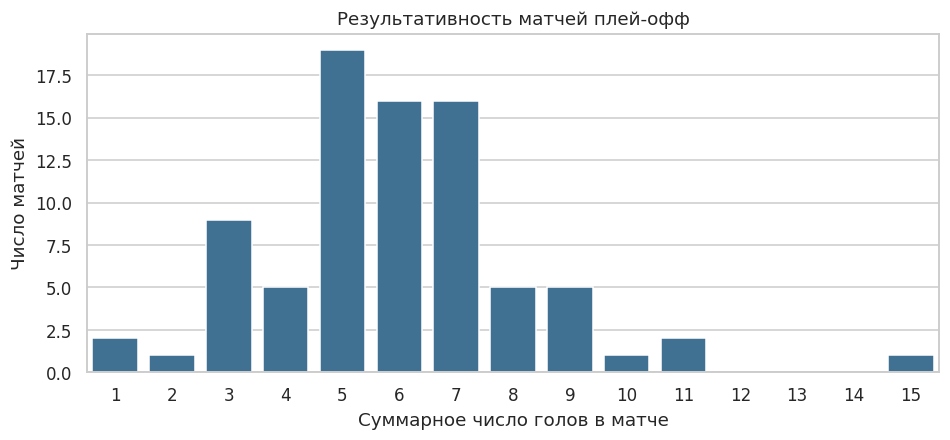

Среднее 5.927, медиана 6.0; середина распределения (Q1–Q3): 5–7 голов.
Мода: 5
Размах 1–15; коэффициент асимметрии 0.777. Редкие высокорезультативные матчи удлиняют правый хвост.


In [6]:
plt.figure(figsize=(10, 4))
sns.countplot(data=games, x='Total Score', order=range(int(games['Total Score'].min()), int(games['Total Score'].max())+1), color='#3274a1')
plt.xlabel('Суммарное число голов в матче')
plt.ylabel('Число матчей')
plt.title('Результативность матчей плей-офф')
finish_plot('05_total_goals.png')
total_goals = games['Total Score']
print(f'Среднее {total_goals.mean():.3f}, медиана {total_goals.median():.1f}; середина распределения (Q1–Q3): {total_goals.quantile(.25):.0f}–{total_goals.quantile(.75):.0f} голов.')
print('Мода:', ', '.join(map(str, total_goals.mode().tolist())))
print(f'Размах {total_goals.min()}–{total_goals.max()}; коэффициент асимметрии {total_goals.skew():.3f}. Редкие высокорезультативные матчи удлиняют правый хвост.')

## 6. Самые результативные и нерезультативные матчи

Найдём игры с минимальным и максимальным числом голов. Здесь важно вывести все совпадения: матчей с одинаковым результатом может быть несколько.

In [7]:
min_goals = games['Total Score'].min()
max_goals = games['Total Score'].max()

print('Самые нерезультативные матчи:')
for game_id in games.index[games['Total Score'] == min_goals]:
    print(gameInfo(game_id))

print('Самые результативные матчи:')
for game_id in games.index[games['Total Score'] == max_goals]:
    print(gameInfo(game_id))

Самые нерезультативные матчи:
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Самые результативные матчи:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


## 7. Сколько игроков участвовало в каждом матче

Соберём имена из всех полей состава обеих команд и добавим вратарей. В условии поля гостей указаны дважды; по смыслу здесь нужны и гости, и хозяева.

Каждого игрока посчитаем только один раз за матч. Это важно и для вратарей: их имена встречаются как в отдельном поле `Goalie`, так и среди игроков на льду. Пустые значения исключим. В итоге учитываем тех, кто хотя бы раз появился на льду в записях; запасные, которые не выходили на площадку, сюда не попадут.

In [8]:
player_cols = []
for side in ['Away', 'Home']:
    for number in range(1, 7):
        player_cols.append(f"{side} Team's Player on the Ice #{number}")

goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]
roster = events[['Game ID'] + player_cols + goalie_cols]

# Переносим имена из разных столбцов в один столбец Player.
appearances = roster.melt(id_vars='Game ID', value_name='Player')
appearances = appearances[['Game ID', 'Player']].dropna()
appearances['Player'] = appearances['Player'].str.strip()
appearances = appearances[appearances['Player'] != '']
appearances = appearances.drop_duplicates()

player_games = appearances.groupby('Player')['Game ID'].nunique()
player_games.name = 'Games'
games['Player Count'] = appearances.groupby('Game ID').size()

most_players = games['Player Count'].max()
max_players = games.loc[games['Player Count'] == most_players, ['Player Count']].copy()
max_players.insert(0, 'Game Info', max_players.index.map(gameInfo))
display(max_players)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Получилось 40 игроков: по 20 у каждой команды. В примере задания для этого же матча указано 41. Вероятная причина расхождения — подсчёт NaN как отдельного значения. Здесь пустые записи не учитываются.

## 8. Расстояние от места броска до ворот

Для каждого незаблокированного броска сначала определим, какие ворота атакует команда. Для этого используем команду, совершившую бросок, и поле `Home Team's Defending Side`. Выбирать просто ближайшие ворота нельзя: игрок может бросать со своей половины площадки.

По условию расстояние нужно считать до ближайшей точки створа шириной 6 футов. Если координата y находится между −3 и 3, достаточно расстояния по горизонтали. В остальных случаях считаем расстояние до ближайшего края створа. Обе ситуации можно записать одной формулой:

`d = sqrt((x − X)² + max(|y| − 3, 0)²)`, где `X` равен 89 или −89.

Все расстояния оставляем в футах.

In [9]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
all_shot_types = shot_types + ['blocked-shot']
shots = events[events['Play Type'].isin(shot_types)].copy()

x_column = 'X Coordinate on the Ice Rink'
y_column = 'Y Coordinate on the Ice Rink'
defending_side = "Home Team's Defending Side"

required_columns = [x_column, y_column, defending_side, 'Team Making the Play']
assert shots[required_columns].notna().all().all()
assert shots[defending_side].isin(['left', 'right']).all()

home_shot = shots['Team Making the Play'] == shots['Home Team']
away_shot = shots['Team Making the Play'] == shots['Away Team']
home_defends_left = shots[defending_side] == 'left'
assert (home_shot | away_shot).all()

# Если хозяева защищают левые ворота, они бросают вправо, а гости — влево.
shoots_right = (home_shot & home_defends_left) | (away_shot & ~home_defends_left)
shots['Target X'] = np.where(shoots_right, 89.0, -89.0)

horizontal_distance = shots[x_column] - shots['Target X']
vertical_distance = (shots[y_column].abs() - 3).clip(lower=0)
shots['Shot Length'] = np.hypot(horizontal_distance, vertical_distance)

shots['Accurate'] = shots['Play Type'].isin(['shot-on-goal', 'goal'])
shots['Shot'] = np.where(shots['Accurate'], 'В створ (включая голы)', 'Мимо')
events['Shot Length'] = shots['Shot Length'].reindex(events.index)

display(shots[['Game ID', 'Play Type', 'Shot Length']])
print('Число незаблокированных бросков:', len(shots))

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Число незаблокированных бросков: 7266


## 9. Сравнение точных бросков и промахов

Теперь сравним расстояния, с которых наносились точные и неточные броски. Точных бросков больше, поэтому простое сравнение количества попаданий в каждый интервал было бы неудобным. Используем плотность и отдельно нормируем каждую группу: для этого нужны `stat='density'` и `common_norm=False`.

Ширину интервалов возьмём одинаковую — 5 футов. Заблокированные броски в этом пункте не рассматриваем.

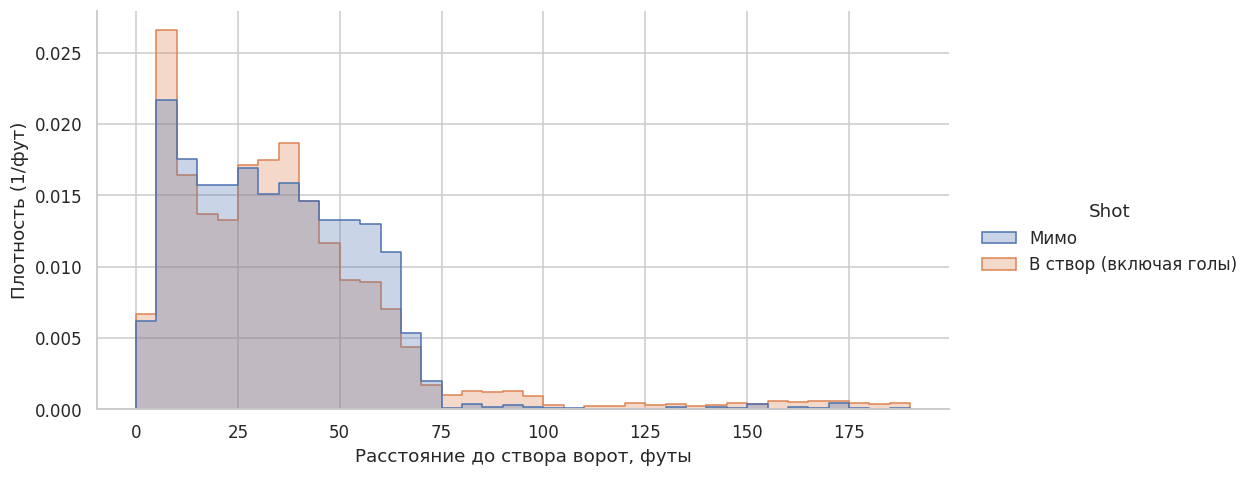

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
В створ (включая голы),4623.000,36.207,29.997,0.000,15.000,31.828,47.011,188.215
Мимо,2643.000,34.014,22.313,0.000,16.155,32.249,49.041,185.068


Play Type,goal,missed-shot,shot-on-goal
Shot,,,
В створ (включая голы),19,0,202
Мимо,0,30,0


Из 251 бросков длиннее 89 футов 26 сделаны при отсутствующем в записи вратаре соперника.


In [10]:
bins = np.arange(0, np.ceil(shots['Shot Length'].max()/5)*5 + 5, 5)
sns.displot(data=shots, x='Shot Length', hue='Shot', bins=bins, stat='density', common_norm=False,
            element='step', alpha=.3, height=4.5, aspect=2)
plt.xlabel('Расстояние до створа ворот, футы')
plt.ylabel('Плотность (1/фут)')
finish_plot('09_shot_distance.png')
display(shots.groupby('Shot')['Shot Length'].describe())
long_shots = shots.loc[shots['Shot Length'].gt(89)]
display(pd.crosstab(long_shots['Shot'], long_shots['Play Type']))
opponent_goalie = shots["Away Team's Goalie"].where(home_shot, shots["Home Team's Goalie"])
print(f'Из {len(long_shots)} бросков длиннее 89 футов {opponent_goalie.loc[long_shots.index].isna().sum()} сделаны при отсутствующем в записи вратаре соперника.')

У точных бросков заметен более высокий пик рядом с воротами, но в остальном распределения сильно перекрываются. Медианы почти одинаковые: 31,828 и 32,249 фута. При этом среднее расстояние у точных бросков даже больше — 36,207 против 34,014 фута. На него влияют редкие очень дальние броски, поэтому вывод «точные броски всегда ближе» был бы неверным.

Длинный хвост может быть связан с дальними бросками и выбросами шайбы, которые дошли до вратаря. Ещё одна возможная причина — попытки забить в пустые ворота. По одной гистограмме нельзя определить, какая из этих причин важнее.

## 10. Доля точных бросков в каждом матче

Для каждой команды в каждом матче разделим число попаданий в створ, включая голы, на все её незаблокированные броски:

`(shot-on-goal + goal) / (shot-on-goal + goal + missed-shot)`.

Сначала создадим строки для обеих команд каждого матча. Если какого-то события не было, поставим ноль — например, команда могла не забить ни одного гола. Если же незаблокированных бросков нет вообще, долю оставим неопределённой (`NaN`): делить на ноль нельзя.

In [11]:
# У каждого матча должны быть две строки — хозяева и гости.
game_list = games.reset_index()
away_games = game_list[['Game ID', 'Away Team']].rename(
    columns={'Away Team': 'Team Making the Play'}
)
home_games = game_list[['Game ID', 'Home Team']].rename(
    columns={'Home Team': 'Team Making the Play'}
)
team_games = pd.concat([away_games, home_games], ignore_index=True)
team_index = pd.MultiIndex.from_frame(team_games).sort_values()

shot_counts = shots.groupby(['Game ID', 'Team Making the Play', 'Play Type']).size()
numshots = shot_counts.unstack('Play Type', fill_value=0)
numshots = numshots.reindex(index=team_index, columns=shot_types, fill_value=0)

numshots['Shot'] = numshots['shot-on-goal'] + numshots['goal']
numshots['Unblocked'] = numshots['Shot'] + numshots['missed-shot']
numshots['Share of Shots on Goal'] = (
    numshots['Shot'] / numshots['Unblocked'].replace(0, np.nan)
)

display(numshots[['Share of Shots on Goal']])
display(numshots['Share of Shots on Goal'].describe().to_frame())

Play Type                        Share of Shots on Goal
Game ID    Team Making the Play                        
2025030111 Boston Bruins                          0.625
           Buffalo Sabres                         0.679
2025030112 Boston Bruins                          0.614
           Buffalo Sabres                         0.636
2025030113 Boston Bruins                          0.694
           Buffalo Sabres                         0.682
2025030114 Boston Bruins                          0.600
           Buffalo Sabres                         0.648
2025030115 Boston Bruins                          0.630
           Buffalo Sabres                         0.491
2025030116 Boston Bruins                          0.667
           Buffalo Sabres                         0.634
2025030121 Montréal Canadiens                     0.655
           Tampa Bay Lightning                    0.622
2025030122 Montréal Canadiens                     0.659
           Tampa Bay Lightning                    0.642
2025030123 Montréal Canadiens                     0.763
           Tampa Bay Lightning                    0.567
2025030124 Montréal Canadiens                     0.562
           Tampa Bay Lightning                    0.476
2025030125 Montréal Canadiens                     0.727
           Tampa Bay Lightning                    0.851
2025030126 Montréal Canadiens                     0.588
           Tampa Bay Lightning                    0.516
2025030127 Montréal Canadiens                     0.391
           Tampa Bay Lightning                    0.707
2025030131 Carolina Hurricanes                    0.558
           Ottawa Senators                        0.611
2025030132 Carolina Hurricanes                    0.590
           Ottawa Senators                        0.549
2025030133 Carolina Hurricanes                    0.587
           Ottawa Senators                        0.688
2025030134 Carolina Hurricanes                    0.577
           Ottawa Senators                        0.692
2025030141 Philadelphia Flyers                    0.541
           Pittsburgh Penguins                    0.621
2025030142 Philadelphia Flyers                    0.800
           Pittsburgh Penguins                    0.540
2025030143 Philadelphia Flyers                    0.707
           Pittsburgh Penguins                    0.569
2025030144 Philadelphia Flyers                    0.714
           Pittsburgh Penguins                    0.512
2025030145 Philadelphia Flyers                    0.476
           Pittsburgh Penguins                    0.500
2025030146 Philadelphia Flyers                    0.821
           Pittsburgh Penguins                    0.583
2025030151 Colorado Avalanche                     0.653
           Los Angeles Kings                      0.581
2025030152 Colorado Avalanche                     0.621
           Los Angeles Kings                      0.676
2025030153 Colorado Avalanche                     0.548
           Los Angeles Kings                      0.634
2025030154 Colorado Avalanche                     0.681
           Los Angeles Kings                      0.676
2025030161 Dallas Stars                           0.778
           Minnesota Wild                         0.784
2025030162 Dallas Stars                           0.681
           Minnesota Wild                         0.698
2025030163 Dallas Stars                           0.692
           Minnesota Wild                         0.696
2025030164 Dallas Stars                           0.682
           Minnesota Wild                         0.656
2025030165 Dallas Stars                           0.512
           Minnesota Wild                         0.737
2025030166 Dallas Stars                           0.676
           Minnesota Wild                         0.583
2025030171 Utah Mammoth                           0.733
           Vegas Golden Knights                   0.620
2025030172 Utah Mammoth                           0.698
           Vegas Golden 

,Share of Shots on Goal
count,164.000
mean,0.639
std,0.085
min,0.353
25%,0.583
50%,0.639
75%,0.689
max,0.860


В среднем по всем парам «команда — матч» в створ попадало 63,9% незаблокированных бросков. В отдельных матчах доля менялась от 35,3% до 86,0%; в половине наблюдений она находилась примерно между 58,3% и 68,9%.

Это доля попаданий в створ, а не голов: вратарь мог отбить точный бросок. Разброс между матчами заметный, поэтому по одной игре судить об общей точности команды сложно.

## 11. Команды с самой высокой и низкой средней точностью

Усредним долю точных бросков по матчам и выведем по пять команд с каждого края рейтинга. Здесь каждый матч имеет одинаковый вес. Это именно среднее матчевых долей: если сначала сложить все броски за плей-офф и только потом найти долю, результат может немного отличаться.

При сравнении стоит помнить, что команды сыграли разное число матчей. Среднее по короткой серии сильнее зависит от отдельных игр.

In [12]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()
print('Пять максимальных средних долей:')
display(avgnumshots.nlargest(5).to_frame())
print('Пять минимальных средних долей:')
display(avgnumshots.nsmallest(5).to_frame())
print(f'Лидер: {avgnumshots.idxmax()} ({avgnumshots.max():.1%}); минимум: {avgnumshots.idxmin()} ({avgnumshots.min():.1%}).')

Пять максимальных средних долей:


,Share of Shots on Goal
Team Making the Play,
Edmonton Oilers,0.706
Philadelphia Flyers,0.684
Dallas Stars,0.670
Minnesota Wild,0.656
Colorado Avalanche,0.653


Пять минимальных средних долей:


,Share of Shots on Goal
Team Making the Play,
Pittsburgh Penguins,0.554
Utah Mammoth,0.599
Carolina Hurricanes,0.615
Tampa Bay Lightning,0.626
Buffalo Sabres,0.626


Лидер: Edmonton Oilers (70.6%); минимум: Pittsburgh Penguins (55.4%).


У Edmonton Oilers самая высокая средняя доля точных бросков — 70,6%, а у Pittsburgh Penguins самая низкая — 55,4%. Здесь сравнивается именно доля попаданий в створ, а не среднее число бросков за матч.

Высокая точность сама по себе не означает высокую результативность: многое зависит от качества бросков и игры вратаря соперника.

## 12. Среднее число бросков в створ и голов за игру

Для каждой команды найдём два показателя: сколько раз она в среднем попадала в створ и сколько забивала за матч. Голы входят в число бросков в створ.

Усреднять будем по всем матчам команды, включая игры без голов. Если их пропустить, средняя результативность получится завышенной.

In [13]:
avgshots = numshots[['Shot', 'goal']].rename(columns={'goal': 'Goal'}).groupby('Team Making the Play').mean()
assert len(avgshots) == 16
assert numshots['goal'].sum() == games['Total Score'].sum()
display(avgshots)

Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13. Связаны ли число бросков и результативность

Нанесём полученные средние на график: по горизонтали — броски в створ, по вертикали — голы. Каждая точка соответствует одной из 16 команд. Линия регрессии поможет увидеть общую связь, а полоса вокруг неё показывает 95%-й доверительный интервал для среднего, рассчитанный методом bootstrap. Для воспроизводимости зададим `seed`.

Такое сравнение не учитывает силу соперников и разное число матчей. Кроме того, голы уже входят в число точных бросков, поэтому два показателя частично связаны самим способом подсчёта.

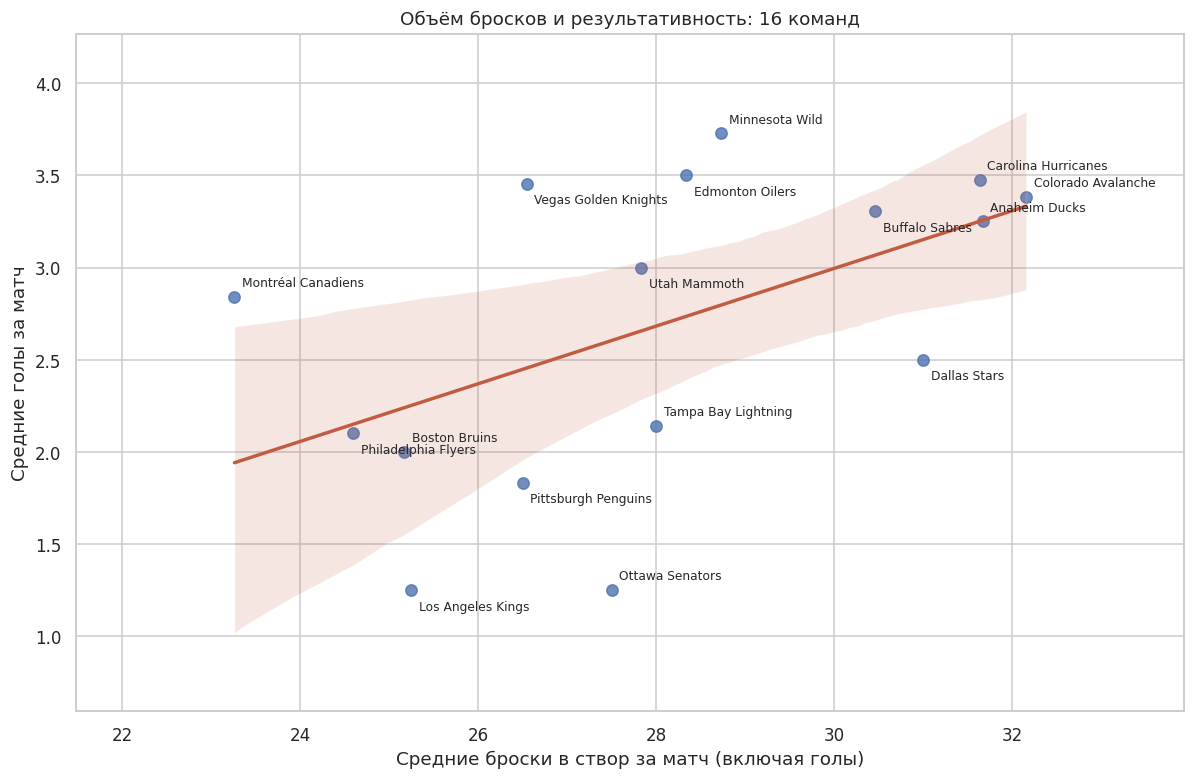

Корреляция Пирсона r = 0.521; R² = 0.271; наклон = 0.156.


In [14]:
fig, ax = plt.subplots(figsize=(13, 8))
sns.regplot(data=avgshots, x='Shot', y='Goal', ax=ax, seed=42, scatter_kws={'s': 55}, line_kws={'color':'#c15b42'})
for n, (team, team_stats) in enumerate(avgshots.sort_values(['Goal', 'Shot']).iterrows()):
    ax.annotate(team, (team_stats['Shot'], team_stats['Goal']), xytext=(5, 7 if n % 2 else -13), textcoords='offset points', fontsize=8)
ax.set(xlabel='Средние броски в створ за матч (включая голы)', ylabel='Средние голы за матч', title='Объём бросков и результативность: 16 команд')
ax.margins(x=.20, y=.15)
finish_plot('13_regression.png')
fit = linregress(avgshots['Shot'], avgshots['Goal'])
print(f'Корреляция Пирсона r = {fit.rvalue:.3f}; R² = {fit.rvalue**2:.3f}; наклон = {fit.slope:.3f}.')

Связь положительная, но не очень сильная: команды, которые больше бросают в створ, обычно больше забивают. Корреляция около 0,52, а R² около 0,27. Точки заметно разбросаны вокруг линии, так что одного числа бросков для объяснения результативности недостаточно. По этому графику нельзя сказать, на сколько голов вырастет счёт, если команда начнёт чаще бросать.

## 14. Матч с наибольшим числом бросковых попыток

Теперь учтём все попытки: попадания в створ, голы, промахи и заблокированные броски. Найдём матч с их максимальным числом. Здесь считаем попытки за всю игру, поэтому матчи с овертаймами могут иметь преимущество по этому показателю.

Если максимум встретится несколько раз, выведем все такие игры. Для карты в следующем пункте возьмём первую из них по ID.

In [15]:
all_shots = events[events['Play Type'].isin(all_shot_types)].copy()
attempts = all_shots.groupby('Game ID').size()
attempts = attempts.reindex(games.index, fill_value=0)

max_attempts = attempts.max()
max_ids = attempts.index[attempts == max_attempts]
idxmax = max_ids[0]

for game_id in max_ids:
    print(gameInfo(game_id), '—', attempts.loc[game_id], 'попыток')

match_shots = all_shots[all_shots['Game ID'] == idxmax].copy()
display(pd.crosstab(match_shots['Team Making the Play'], match_shots['Play Type']))

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20) — 208 попыток


Play Type,blocked-shot,goal,missed-shot,shot-on-goal
Team Making the Play,,,,
Carolina Hurricanes,26,3,34,46
Ottawa Senators,28,2,32,37


## 15. Карта бросков

Нарисуем площадку с помощью `plot_rink` из приложенного файла `rink.py` и нанесём на неё попытки из найденного матча. Цветом отметим исход броска, а формой точки — команду.

Для удобства сделаем так, чтобы хозяева всегда атаковали вправо, а гости — влево. В этом матче в нечётных периодах нужно поменять знак обеих координат: `(x, y) → (−x, −y)`. Заодно проверим это по полю стороны защиты хозяев.

Для заблокированных бросков есть особенность: координаты относятся к записанному событию блокировки и могут не совпадать с местом, откуда игрок выпустил шайбу.

Событий без координат: 0


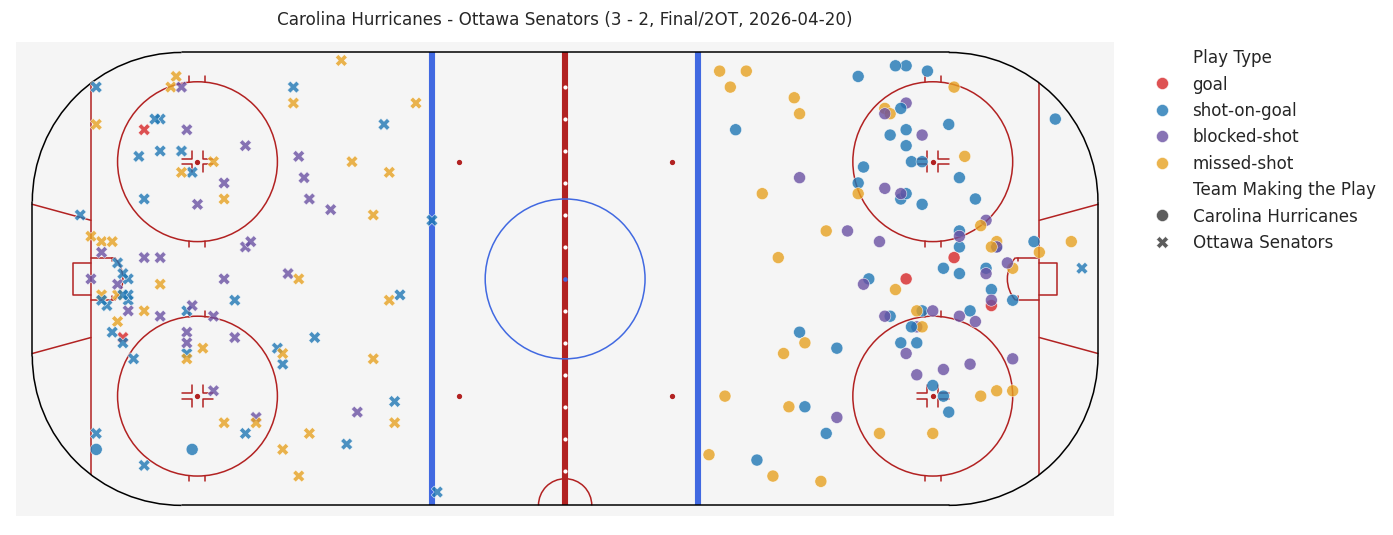

In [16]:
# Добавляем папку датасета, чтобы импортировать приложенный rink.py.
sys.path.insert(0, str(data_dir.resolve()))
from rink import plot_rink
match_shots = all_shots.loc[all_shots['Game ID'].eq(idxmax)].copy()
flip = match_shots[defending_side].eq('right')
assert flip.eq(match_shots['Period'].mod(2).eq(1)).all()
match_shots['Plot X'] = match_shots[x_column] * np.where(flip, -1, 1)
match_shots['Plot Y'] = match_shots[y_column] * np.where(flip, -1, 1)
print('Событий без координат:', match_shots[['Plot X', 'Plot Y']].isna().any(axis=1).sum())
plt.figure(figsize=(13, 6))
plot_rink()
sns.scatterplot(data=match_shots, x='Plot X', y='Plot Y', hue='Play Type', style='Team Making the Play',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette={'goal':'#d62728','shot-on-goal':'#1f77b4','blocked-shot':'#6a51a3','missed-shot':'#e6a122'},
                s=62, alpha=.8, edgecolor='white', linewidth=.4)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlim(-104, 104)
plt.ylim(-46, 46)
plt.axis('off')
plt.title(gameInfo(idxmax), fontsize=11)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
finish_plot('15_shot_map.png')

На карте есть и попытки со своей половины площадки. Поэтому ближайшие к точке ворота не обязательно были целью броска: направление атаки мы определили по команде и стороне защиты в этом периоде.

## 16. Десять лучших снайперов

Отберём голы и посчитаем, сколько раз каждый игрок указан в `Player in the Event #1` — это автор гола.

В этом и следующих рейтингах выведем ровно десять игроков. При равных показателях расположим их по алфавиту. Также укажем, сколько игроков имеют такой же результат, как десятый: их места в рейтинге условны.

In [17]:
def ranking(values, column, n=10):
    """Выбираем первых n игроков; равные результаты сортируем по имени."""
    table = values.rename(column).rename_axis('Player').reset_index()
    table = table.sort_values([column, 'Player'], ascending=[False, True])
    table = table.set_index('Player')

    if len(table) >= n:
        last_value = table[column].iloc[n - 1]
        tied_players = (table[column] == last_value).sum()
        print(f'Граница топ-{n}: {last_value:.3f}; игроков с этим значением: {tied_players}')

    return table.head(n)

goal_counts = goals['Player in the Event #1'].value_counts()
top_goals = ranking(goal_counts, 'Goals')
display(top_goals)

Граница топ-10: 7.000; игроков с этим значением: 6


,Goals
Player,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Alex Newhook,7
Jackson Blake,7
Mark Stone,7


## 17. Десять лучших ассистентов

Авторы голевых передач записаны во втором и третьем полях участников гола. Объединим эти два столбца и посчитаем передачи каждого игрока. Пустые значения уберём: у гола может быть одна передача или вообще ни одной.

In [18]:
first_assists = goals['Player in the Event #2']
second_assists = goals['Player in the Event #3']
all_assists = pd.concat([first_assists, second_assists], ignore_index=True)
assist_counts = all_assists.dropna().value_counts()

top_assists = ranking(assist_counts, 'Assists')
display(top_assists)

Граница топ-10: 11.000; игроков с этим значением: 2


,Assists
Player,
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Taylor Hall,12
Kirill Kaprizov,11


## 18. Десять лучших игроков по системе «гол + пас»

Сложим для каждого игрока голы и результативные передачи. Если игрок есть только в одном из списков, отсутствующий показатель примем за ноль. Рядом с общим числом очков оставим голы и передачи, чтобы было видно, из чего складывается результат.

In [19]:
scoring = pd.concat([goal_counts.rename('Goals'), assist_counts.rename('Assists')], axis=1).fillna(0).astype(int)
scoring['Points'] = scoring['Goals'] + scoring['Assists']
top_points = ranking(scoring['Points'], 'Points').join(scoring[['Goals', 'Assists']])
display(top_points)
assert scoring['Goals'].sum() == len(goals)
assert scoring['Points'].sum() == len(goals) + assist_counts.sum()

Граница топ-10: 16.000; игроков с этим значением: 4


,Points,Goals,Assists
Player,,,
Mitch Marner,29,10,19
Jack Eichel,22,2,20
Jackson Blake,20,7,13
Taylor Hall,19,7,12
Brett Howden,18,14,4
Nikolaj Ehlers,18,8,10
Shea Theodore,18,6,12
Lane Hutson,16,3,13
Logan Stankoven,16,11,5


## 19. Кто чаще бросал в створ в среднем за матч

Посчитаем точные броски каждого игрока, включая голы, и разделим на число его матчей из пункта 7. Здесь нужно учитывать и игры, в которых он ни разу не бросил: иначе среднее окажется завышенным.

Рядом со средним выведем общее число бросков и сыгранных матчей. Это поможет отличить высокий результат на длинной дистанции от показателя за несколько игр. Минимального числа матчей в условии нет, поэтому дополнительный порог вводить не будем.

In [20]:
accurate_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
player_shots = accurate_shots['Player in the Event #1'].value_counts()

# Игры без бросков тоже входят в среднее.
shooter_rates = player_games.to_frame()
shooter_rates['Shots on Goal'] = player_shots.reindex(player_games.index, fill_value=0)
shooter_rates['Per Game'] = shooter_rates['Shots on Goal'] / shooter_rates['Games']

top_shooters = ranking(shooter_rates['Per Game'], 'Per Game')
top_shooters = top_shooters.join(shooter_rates[['Games', 'Shots on Goal']])
display(top_shooters)

Граница топ-10: 3.615; игроков с этим значением: 1


,Per Game,Games,Shots on Goal
Player,,,
Jason Robertson,5.000,6,30
Dylan Guenther,4.500,6,27
Nikita Kucherov,4.429,7,31
Matt Boldy,4.364,11,48
Quinton Byfield,4.250,4,17
Darren Raddysh,4.000,7,28
Joel Eriksson Ek,4.000,6,24
Alex Laferriere,3.750,4,15
David Pastrnak,3.667,6,22


## 20. Кто чаще проводил силовые приёмы

Аналогично посчитаем среднее число силовых приёмов за матч. У события `hit` первый игрок проводит приём, а второй его получает, поэтому используем `Player in the Event #1`. Как и в предыдущем пункте, делим на все матчи игрока, в том числе те, где он не провёл ни одного силового приёма.

In [21]:
hits = events[events['Play Type'] == 'hit']
player_hits = hits['Player in the Event #1'].value_counts()

hit_rates = player_games.to_frame()
hit_rates['Hits'] = player_hits.reindex(player_games.index, fill_value=0)
hit_rates['Per Game'] = hit_rates['Hits'] / hit_rates['Games']

top_hitters = ranking(hit_rates['Per Game'], 'Per Game')
top_hitters = top_hitters.join(hit_rates[['Games', 'Hits']])
display(top_hitters)

Граница топ-10: 4.833; игроков с этим значением: 1


,Per Game,Games,Hits
Player,,,
Lawson Crouse,6.333,6,38
Alex Turcotte,6.000,1,6
Alexander Petrovic,6.000,1,6
Yakov Trenin,5.667,9,51
Dylan Cozens,5.500,4,22
Vasily Podkolzin,5.333,6,32
Carl Grundstrom,5.000,3,15
Ivan Barbashev,5.000,22,110
Marcus Foligno,5.000,11,55


## 21. Вратари с матчами без пропущенных голов

По условию подходят и вратари, которые сыграли только часть матча, но за это время не пропустили. Поэтому просто выбрать команды с нулём пропущенных недостаточно: команда могла пропустить до выхода другого вратаря или после его замены.

Сначала найдём все пары «матч — вратарь». Затем для каждого гола посмотрим, кто защищал ворота соперника в этот момент, и запишем пропущенную шайбу этому вратарю. Если поле вратаря пустое, будем считать, что гол забит в пустые ворота, и никому его не припишем. После этого выберем пары с нулём пропущенных.

Расчёт опирается на состав, указанный в момент события. Если пустое поле `Goalie` связано с ошибкой данных, а не с уходом вратаря, это можно выяснить только при проверке протокола матча.

In [22]:
# Список всех вратарей, выходивших на лёд в каждом матче.
goalie_apps = events[['Game ID'] + goalie_cols].melt(
    id_vars='Game ID', value_name='Goalie'
)
goalie_apps = goalie_apps[['Game ID', 'Goalie']].dropna().drop_duplicates()
goalie_index = pd.MultiIndex.from_frame(goalie_apps).sort_values()

# Если забили хозяева, шайбу пропустил вратарь гостей, и наоборот.
home_scored = goals['Team Making the Play'] == goals['Home Team']
goals['Conceding Goalie'] = goals["Home Team's Goalie"]
goals.loc[home_scored, 'Conceding Goalie'] = goals.loc[home_scored, "Away Team's Goalie"]

goals_with_goalie = goals.dropna(subset=['Conceding Goalie'])
conceded = goals_with_goalie.groupby(['Game ID', 'Conceding Goalie']).size()
conceded.index = conceded.index.set_names(['Game ID', 'Goalie'])

# Вратарям без пропущенных голов добавляем нули.
goalie_game = conceded.reindex(goalie_index, fill_value=0).to_frame('Goals Against')
empty_net_goals = goals['Conceding Goalie'].isna().sum()
assert goalie_game['Goals Against'].sum() + empty_net_goals == len(goals)

zero_goalie_games = goalie_game[goalie_game['Goals Against'] == 0].reset_index()
zero_goalie_games['Game Info'] = zero_goalie_games['Game ID'].map(gameInfo)
zero_summary = zero_goalie_games.groupby('Goalie').size()
zero_summary = zero_summary.sort_index().to_frame('Матчи без пропущенных')

print(f'Голов без вратаря в записи: {empty_net_goals}. Вратарей, удовлетворяющих условию: {len(zero_summary)}.')
display(zero_summary)
display(zero_goalie_games[['Goalie', 'Game ID', 'Game Info', 'Goals Against']].sort_values(['Goalie', 'Game ID']))

Голов без вратаря в записи: 25. Вратарей, удовлетворяющих условию: 8.


,Матчи без пропущенных
Goalie,
Andrei Vasilevskiy,1
Arturs Silovs,1
Brandon Bussi,2
Dan Vladar,2
Frederik Andersen,3
Jakub Dobes,1
Joonas Korpisalo,1
Scott Wedgewood,1


,Goalie,Game ID,Game Info,Goals Against
1,Andrei Vasilevskiy,2025030126,Montréal Canadiens - Tampa Bay Lightning (0 - ...,0
5,Arturs Silovs,2025030146,Philadelphia Flyers - Pittsburgh Penguins (1 -...,0
10,Brandon Bussi,2025030413,Vegas Golden Knights - Carolina Hurricanes (5 ...,0
11,Brandon Bussi,2025030416,Vegas Golden Knights - Carolina Hurricanes (0 ...,0
4,Dan Vladar,2025030142,Pittsburgh Penguins - Philadelphia Flyers (0 -...,0
6,Dan Vladar,2025030146,Philadelphia Flyers - Pittsburgh Penguins (1 -...,0
3,Frederik Andersen,2025030131,"Carolina Hurricanes - Ottawa Senators (2 - 0, ...",0
7,Frederik Andersen,2025030221,Carolina Hurricanes - Philadelphia Flyers (3 -...,0
9,Frederik Andersen,2025030314,Montréal Canadiens - Carolina Hurricanes (0 - ...,0
2,Jakub Dobes,2025030126,Montréal Canadiens - Tampa Bay Lightning (0 - ...,0


## 22. Как расстояние до ворот связано с реализацией бросков

Проверим, действительно ли с близкой дистанции забивают чаще. Разделим незаблокированные броски на интервалы: 0–15, 15–30, 30–45, 45–60, 60–90 и 90+ футов. Левая граница входит в интервал, правая — нет. В каждой группе найдём долю бросков, закончившихся голом.

Отдельно повторим расчёт для попыток, при которых у соперника был вратарь. Так можно проверить, объясняются ли результаты дальних бросков игрой по пустым воротам.

На графике также покажем 95%-е интервалы Уилсона. Они помогают оценить, насколько точна полученная доля при данном числе попыток. В этом расчёте броски считаются независимыми, хотя события внутри одного матча могут быть связаны. Угол броска, качество момента и сила соперников здесь не учитываются, поэтому выводы относятся к наблюдаемой связи, а не к отдельному влиянию дистанции.

Все незаблокированные попытки:


,Attempts,Goals,Conversion,CI low,CI high
Distance Band,,,,,
0–15,1748,203,0.116,0.102,0.132
15–30,1657,140,0.084,0.072,0.099
30–45,1775,84,0.047,0.038,0.058
45–60,1209,30,0.025,0.017,0.035
60–90,637,12,0.019,0.011,0.033
90+,240,17,0.071,0.045,0.110


Только при присутствующем вратаре соперника:


,Attempts,Goals,Conversion,CI low,CI high
Distance Band,,,,,
0–15,1741,196,0.113,0.099,0.128
15–30,1652,135,0.082,0.069,0.096
30–45,1768,77,0.044,0.035,0.054
45–60,1202,28,0.023,0.016,0.033
60–90,627,11,0.018,0.010,0.031
90+,214,14,0.065,0.039,0.107


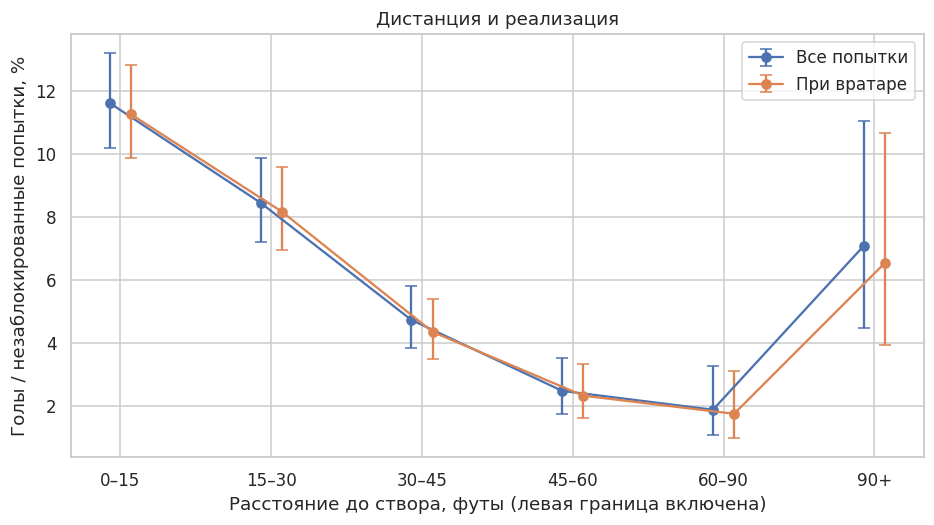

При вратаре реализация с 0–15 футов: 11.26% (196/1741), с 90+ футов: 6.54% (14/214).


In [23]:
shots['Empty Net'] = opponent_goalie.isna()
shots['Distance Band'] = pd.cut(shots['Shot Length'], [0, 15, 30, 45, 60, 90, np.inf], right=False,
                               labels=['0–15', '15–30', '30–45', '45–60', '60–90', '90+'])
shots['Is Goal'] = shots['Play Type'].eq('goal')
def conversion_table(frame):
    table = frame.groupby('Distance Band', observed=False)['Is Goal'].agg(Attempts='size', Goals='sum')
    n = table['Attempts'].replace(0, np.nan)
    p = table['Goals'] / n
    z = 1.959963984540054
    center = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    table['Conversion'] = p
    table['CI low'] = center-half
    table['CI high'] = center+half
    return table

conversion_all = conversion_table(shots)
conversion_goalie = conversion_table(shots.loc[~shots['Empty Net']])
print('Все незаблокированные попытки:')
display(conversion_all)
print('Только при присутствующем вратаре соперника:')
display(conversion_goalie)
fig, ax = plt.subplots(figsize=(10, 5))
for table, shift, label in [(conversion_all, -.07, 'Все попытки'), (conversion_goalie, .07, 'При вратаре')]:
    p = table['Conversion']
    ax.errorbar(np.arange(len(table))+shift, p*100,
                yerr=np.vstack([p-table['CI low'], table['CI high']-p])*100,
                fmt='o-', capsize=4, label=label)
ax.set_xticks(np.arange(len(conversion_all)), conversion_all.index.astype(str))
ax.set(xlabel='Расстояние до створа, футы (левая граница включена)', ylabel='Голы / незаблокированные попытки, %', title='Дистанция и реализация')
ax.legend()
finish_plot('22_conversion.png')
near = conversion_goalie.iloc[0]
far = conversion_goalie.iloc[-1]
print(f"При вратаре реализация с 0–15 футов: {near['Conversion']:.2%} ({int(near['Goals'])}/{int(near['Attempts'])}), с 90+ футов: {far['Conversion']:.2%} ({int(far['Goals'])}/{int(far['Attempts'])}).")

До 90 футов результат соответствует ожиданию: чем дальше от ворот, тем ниже доля голов. Но в последней группе она снова растёт — до 7,08% для всех попыток и 6,54% для бросков при вратаре. Причём 14 из 17 голов с дистанции 90+ футов записаны при присутствующем вратаре. Значит, одними пустыми воротами этот подъём объяснить не получается. Стоило бы отдельно проверить эти эпизоды: дело может быть как в особенностях моментов, так и в ошибках координат или стороны защиты. В целом ближние броски результативнее, но плавного снижения на всём диапазоне в этих данных нет.

## Проверка и сохранение результатов

В конце проверим основные числа: количество событий, матчей и голов, а также несколько результатов из примеров задания. Эти проверки относятся к приложенному файлу; для другого набора данных числа могут быть другими.

Таблицы сохраним в CSV, а рисунки — в PNG. Для CSV используем `utf-8-sig`, чтобы русские подписи корректно открывались в Excel.

In [24]:
assert events.shape[0] == 29710
assert len(games) == 82 and len(shots) == 7266 and len(numshots) == 164
assert games['Total Score'].sum() == 486
assert games['Total Score'].min() == 1 and games['Total Score'].max() == 15
assert games['Player Count'].max() == 40  # В примере PDF, вероятно, посчитан также NaN.
assert idxmax == 2025030132
assert np.isclose(avgnumshots.loc['Edmonton Oilers'], .706, atol=.0005)
assert np.isclose(avgshots.loc['Anaheim Ducks', 'Shot'], 31.667, atol=.0005)
tables = {'games': games, 'shots_by_team_game': numshots, 'average_accuracy': avgnumshots,
          'average_shots_goals': avgshots, 'top_goals': top_goals, 'top_assists': top_assists,
          'top_points': top_points, 'top_shooters': top_shooters, 'top_hitters': top_hitters,
          'goalie_games': goalie_game, 'zero_goalie_games': zero_goalie_games,
          'conversion_all': conversion_all, 'conversion_with_goalie': conversion_goalie}
for name, table in tables.items():
    table.to_csv(output_dir / f'{name}.csv', encoding='utf-8-sig')
print('Все проверки пройдены. Таблицы и рисунки сохранены в:', output_dir)

Все проверки пройдены. Таблицы и рисунки сохранены в: /kaggle/working/final_exam_results
